In [ ]:
!pip install -q qiskit qiskit-aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 43.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 2.5 MB/s eta 0:00:00


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from tensorflow.keras.datasets import mnist

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

In [ ]:
# ==========================================
# Load MNIST Dataset
# ==========================================

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set: (60000, 28, 28)
Testing set : (10000, 28, 28)


Digit: 7
Original shape: (28, 28)
Resized shape : (16, 16)


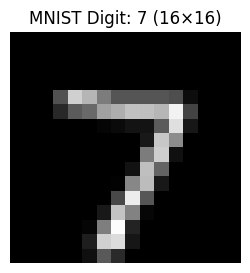

In [ ]:
# ==========================================
# Prepare one 16×16 MNIST image
# ==========================================

image_index = 0

image_16 = cv2.resize(
    X_test[image_index],
    (16, 16),
    interpolation=cv2.INTER_AREA
)

print("Digit:", y_test[image_index])
print("Original shape:", X_test[image_index].shape)
print("Resized shape :", image_16.shape)

plt.figure(figsize=(3, 3))
plt.imshow(image_16, cmap="gray", vmin=0, vmax=255)
plt.title(f"MNIST Digit: {y_test[image_index]} (16×16)")
plt.axis("off")
plt.show()

In [ ]:
# ==========================================
# Fixed Patch Representation
# ==========================================

def create_fixed_patches(image, patch_size):

    h, w = image.shape

    patch_values = []
    patch_positions = []

    for row in range(0, h, patch_size):

        for col in range(0, w, patch_size):

            patch = image[
                row:row + patch_size,
                col:col + patch_size
            ]

            # Mean intensity represents the patch
            mean_intensity = np.mean(patch)

            patch_values.append(mean_intensity)
            patch_positions.append((row, col))

    return np.array(patch_values), patch_positions

In [ ]:
# ==========================================
# Verify Fixed Patch Counts
# ==========================================

for patch_size in [8, 4, 2]:

    patch_values, patch_positions = create_fixed_patches(
        image_16,
        patch_size
    )

    print(
        f"{patch_size}×{patch_size} patches "
        f"-> {len(patch_values)} elements"
    )

8×8 patches -> 4 elements
4×4 patches -> 16 elements
2×2 patches -> 64 elements


In [ ]:
# ==========================================
# Fixed 8×8 Patch Representation
# ==========================================

patch_size = 8

patch_values, patch_positions = create_fixed_patches(
    image_16,
    patch_size
)

print("Patch size       :", patch_size)
print("Number of patches:", len(patch_values))
print("\nPatch mean intensities:")
print(patch_values)

Patch size       : 8
Number of patches: 4

Patch mean intensities:
[19.796875 30.609375 20.03125  23.71875 ]


In [ ]:
# ==========================================
# Convert Patch Intensities to FRQI Angles
# ==========================================

theta = (
    patch_values.astype(np.float64) / 255.0
) * (np.pi / 2)

print("Patch intensities:")
print(patch_values)

print("\nFRQI angles:")
print(theta)

Patch intensities:
[19.796875 30.609375 20.03125  23.71875 ]

FRQI angles:
[0.12194846 0.18855331 0.12339221 0.14610716]


In [ ]:
# ==========================================
# FRQI Parameters for Fixed Patches
# ==========================================

num_elements = len(theta)

position_qubits_count = int(
    np.log2(num_elements)
)

intensity_qubit = 0

position_qubits = list(
    range(1, position_qubits_count + 1)
)

total_qubits = position_qubits_count + 1

print("Number of patch elements :", num_elements)
print("Position qubits          :", position_qubits_count)
print("Intensity qubit          :", intensity_qubit)
print("Total qubits             :", total_qubits)

Number of patch elements : 4
Position qubits          : 2
Intensity qubit          : 0
Total qubits             : 3


In [ ]:
# ==========================================
# Create Fixed-Patch FRQI Circuit
# ==========================================

qc_fixed = QuantumCircuit(total_qubits)

# Create equal superposition of patch positions
for q in position_qubits:
    qc_fixed.h(q)

# Encode each patch mean intensity
for patch_index, angle in enumerate(theta):

    binary = format(
        patch_index,
        f"0{len(position_qubits)}b"
    )

    # Same little-endian correction
    # used in Conventional FRQI
    binary = binary[::-1]

    # Convert zero controls using X gates
    for q, bit in zip(
        position_qubits,
        binary
    ):

        if bit == "0":
            qc_fixed.x(q)

    # Controlled Ry rotation
    qc_fixed.mcry(
        2 * angle,
        position_qubits,
        intensity_qubit
    )

    # Undo X gates
    for q, bit in zip(
        position_qubits,
        binary
    ):

        if bit == "0":
            qc_fixed.x(q)

print("Fixed 8×8 FRQI circuit created successfully.")

Fixed 8×8 FRQI circuit created successfully.


In [ ]:
# ==========================================
# Quantum Resource Measurement
# ==========================================

print("Fixed Patch Size :", f"{patch_size}×{patch_size}")
print("Patch Elements   :", num_elements)
print("Qubits           :", qc_fixed.num_qubits)
print("Gates            :", qc_fixed.size())
print("Circuit Depth    :", qc_fixed.depth())

Fixed Patch Size : 8×8
Patch Elements   : 4
Qubits           : 3
Gates            : 26
Circuit Depth    : 18


In [ ]:
print(qc_fixed.draw("text"))

     ┌─────────────┐     ┌───┐┌──────────────┐┌───┐┌─────────────┐     ┌───┐»
q_0: ┤ Ry(0.12195) ├─────┤ X ├┤ Ry(-0.12195) ├┤ X ├┤ Ry(0.18855) ├─────┤ X ├»
     └────┬───┬────┘┌───┐└─┬─┘└──────────────┘└─┬─┘└────┬───┬────┘     └─┬─┘»
q_1: ─────┤ H ├─────┤ X ├──■────────────────────■───────┤ X ├────────────■──»
          ├───┤     ├───┤  │                    │       ├───┤     ┌───┐  │  »
q_2: ─────┤ H ├─────┤ X ├──■────────────────────■───────┤ X ├─────┤ X ├──■──»
          └───┘     └───┘                               └───┘     └───┘     »
«     ┌──────────────┐┌───┐┌─────────────┐┌───┐┌──────────────┐┌───┐»
«q_0: ┤ Ry(-0.18855) ├┤ X ├┤ Ry(0.12339) ├┤ X ├┤ Ry(-0.12339) ├┤ X ├»
«     └──────────────┘└─┬─┘└────┬───┬────┘└─┬─┘└──────────────┘└─┬─┘»
«q_1: ──────────────────■───────┤ X ├───────■────────────────────■──»
«                       │       ├───┤       │                    │  »
«q_2: ──────────────────■───────┤ X ├───────■────────────────────■──»
«                               └─

In [ ]:
# ==========================================
# Obtain FRQI Statevector
# ==========================================

statevector_fixed = Statevector.from_instruction(
    qc_fixed
)

print("Statevector obtained successfully.")
print("Statevector dimension:", len(statevector_fixed))

Statevector obtained successfully.
Statevector dimension: 8


In [ ]:
# ==========================================
# Extract FRQI Intensity Information
# ==========================================

state = statevector_fixed.data

probabilities = np.abs(state) ** 2

print("State probabilities:")
print(probabilities)

State probabilities:
[0.24630054 0.00369946 0.24121675 0.00878325 0.24621287 0.00378713
 0.24470104 0.00529896]


In [ ]:
# ==========================================
# Recover FRQI Patch Angles
# ==========================================

state = statevector_fixed.data

recovered_angles = []

for patch_index in range(num_elements):

    # Qubit 0 is the intensity qubit.
    # Therefore:
    # intensity = 0 -> even index
    # intensity = 1 -> odd index

    index_zero = 2 * patch_index
    index_one = 2 * patch_index + 1

    amplitude_zero = np.abs(
        state[index_zero]
    )

    amplitude_one = np.abs(
        state[index_one]
    )

    # Recover theta from:
    # |psi> = cos(theta)|0> + sin(theta)|1>

    angle = np.arctan2(
        amplitude_one,
        amplitude_zero
    )

    recovered_angles.append(angle)

recovered_angles = np.array(
    recovered_angles
)

print("Original angles:")
print(theta)

print("\nRecovered angles:")
print(recovered_angles)

Original angles:
[0.12194846 0.18855331 0.12339221 0.14610716]

Recovered angles:
[0.12194846 0.18855331 0.12339221 0.14610716]


In [ ]:
# ==========================================
# Recover Patch Intensities
# ==========================================

recovered_patch_values = (
    recovered_angles / (np.pi / 2)
) * 255.0

recovered_patch_values = np.clip(
    recovered_patch_values,
    0,
    255
)

print("Original patch intensities:")
print(patch_values)

print("\nRecovered patch intensities:")
print(recovered_patch_values)

Original patch intensities:
[19.796875 30.609375 20.03125  23.71875 ]

Recovered patch intensities:
[19.796875 30.609375 20.03125  23.71875 ]


In [ ]:
# ==========================================
# Reconstruct Image from FRQI Patches
# ==========================================

frqi_reconstructed = np.zeros(
    image_16.shape,
    dtype=np.float64
)

for value, (row, col) in zip(
    recovered_patch_values,
    patch_positions
):

    frqi_reconstructed[
        row:row + patch_size,
        col:col + patch_size
    ] = value

In [ ]:
# ==========================================
# FRQI Reconstruction Metrics
# ==========================================

mse = mean_squared_error(
    image_16,
    frqi_reconstructed
)

psnr = peak_signal_noise_ratio(
    image_16,
    frqi_reconstructed,
    data_range=255
)

ssim = structural_similarity(
    image_16,
    frqi_reconstructed,
    data_range=255
)

print("Fixed 8×8 FRQI Results")
print("----------------------------")
print("Patch Elements :", num_elements)
print("Qubits         :", qc_fixed.num_qubits)
print("Gates          :", qc_fixed.size())
print("Depth          :", qc_fixed.depth())
print(f"MSE            : {mse:.4f}")
print(f"PSNR           : {psnr:.4f} dB")
print(f"SSIM           : {ssim:.4f}")

Fixed 8×8 FRQI Results
----------------------------
Patch Elements : 4
Qubits         : 3
Gates          : 26
Depth          : 18
MSE            : 3204.6737
PSNR           : 13.0730 dB
SSIM           : 0.0213


In [ ]:
# ==========================================
# FRQI Reconstruction Metrics
# ==========================================

mse = mean_squared_error(
    image_16,
    frqi_reconstructed
)

psnr = peak_signal_noise_ratio(
    image_16,
    frqi_reconstructed,
    data_range=255
)

ssim = structural_similarity(
    image_16,
    frqi_reconstructed,
    data_range=255
)

print("Fixed 8×8 FRQI Results")
print("----------------------------")
print("Patch Elements :", num_elements)
print("Qubits         :", qc_fixed.num_qubits)
print("Gates          :", qc_fixed.size())
print("Depth          :", qc_fixed.depth())
print(f"MSE            : {mse:.4f}")
print(f"PSNR           : {psnr:.4f} dB")
print(f"SSIM           : {ssim:.4f}")

Fixed 8×8 FRQI Results
----------------------------
Patch Elements : 4
Qubits         : 3
Gates          : 26
Depth          : 18
MSE            : 3204.6737
PSNR           : 13.0730 dB
SSIM           : 0.0213


In [ ]:
# ==========================================
# Complete Fixed-Patch FRQI Experiment
# ==========================================

def run_fixed_frqi(image, patch_size):

    # --------------------------------------
    # 1. Create fixed patches
    # --------------------------------------

    patch_values, patch_positions = create_fixed_patches(
        image,
        patch_size
    )

    # --------------------------------------
    # 2. Convert intensity to FRQI angles
    # --------------------------------------

    theta = (
        patch_values.astype(np.float64) / 255.0
    ) * (np.pi / 2)

    num_elements = len(theta)

    # --------------------------------------
    # 3. FRQI qubit configuration
    # --------------------------------------

    position_qubits_count = int(
        np.log2(num_elements)
    )

    intensity_qubit = 0

    position_qubits = list(
        range(1, position_qubits_count + 1)
    )

    total_qubits = (
        position_qubits_count + 1
    )

    # --------------------------------------
    # 4. Create FRQI circuit
    # --------------------------------------

    qc = QuantumCircuit(total_qubits)

    # Position superposition
    for q in position_qubits:
        qc.h(q)

    # Encode patch intensities
    for patch_index, angle in enumerate(theta):

        binary = format(
            patch_index,
            f"0{len(position_qubits)}b"
        )

        # Qiskit little-endian ordering
        binary = binary[::-1]

        # Convert zero controls
        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":
                qc.x(q)

        # Controlled rotation
        qc.mcry(
            2 * angle,
            position_qubits,
            intensity_qubit
        )

        # Undo X gates
        for q, bit in zip(
            position_qubits,
            binary
        ):

            if bit == "0":
                qc.x(q)

    # --------------------------------------
    # 5. Statevector
    # --------------------------------------

    statevector = Statevector.from_instruction(qc)

    state = statevector.data

    # --------------------------------------
    # 6. Recover patch intensities
    # --------------------------------------

    recovered_angles = []

    for patch_index in range(num_elements):

        index_zero = 2 * patch_index
        index_one = 2 * patch_index + 1

        amplitude_zero = np.abs(
            state[index_zero]
        )

        amplitude_one = np.abs(
            state[index_one]
        )

        angle = np.arctan2(
            amplitude_one,
            amplitude_zero
        )

        recovered_angles.append(angle)

    recovered_angles = np.array(
        recovered_angles
    )

    # --------------------------------------
    # 7. Convert angles → intensities
    # --------------------------------------

    recovered_patch_values = (
        recovered_angles / (np.pi / 2)
    ) * 255.0

    recovered_patch_values = np.clip(
        recovered_patch_values,
        0,
        255
    )

    # --------------------------------------
    # 8. Reconstruct image
    # --------------------------------------

    reconstructed = np.zeros(
        image.shape,
        dtype=np.float64
    )

    for value, (row, col) in zip(
        recovered_patch_values,
        patch_positions
    ):

        reconstructed[
            row:row + patch_size,
            col:col + patch_size
        ] = value

    # --------------------------------------
    # 9. Image-quality metrics
    # --------------------------------------

    mse = mean_squared_error(
        image,
        reconstructed
    )

    psnr = peak_signal_noise_ratio(
        image,
        reconstructed,
        data_range=255
    )

    ssim = structural_similarity(
        image,
        reconstructed,
        data_range=255
    )

    # --------------------------------------
    # 10. Return results
    # --------------------------------------

    return {
        "Patch Size": f"{patch_size}×{patch_size}",
        "Patch Elements": num_elements,
        "Qubits": qc.num_qubits,
        "Gates": qc.size(),
        "Depth": qc.depth(),
        "MSE": mse,
        "PSNR": psnr,
        "SSIM": ssim,
        "Circuit": qc,
        "Reconstructed": reconstructed
    }

In [ ]:
# ==========================================
# Run Fixed-Patch FRQI for all patch sizes
# ==========================================

fixed_frqi_results = []

for patch_size in [8, 4, 2]:

    result = run_fixed_frqi(
        image_16,
        patch_size
    )

    fixed_frqi_results.append(result)

    print(
        f"\nFixed {patch_size}×{patch_size} FRQI"
    )

    print(
        "Elements:",
        result["Patch Elements"]
    )

    print(
        "Qubits:",
        result["Qubits"]
    )

    print(
        "Gates:",
        result["Gates"]
    )

    print(
        "Depth:",
        result["Depth"]
    )

    print(
        f"MSE: {result['MSE']:.4f}"
    )

    print(
        f"PSNR: {result['PSNR']:.4f} dB"
    )

    print(
        f"SSIM: {result['SSIM']:.4f}"
    )


Fixed 8×8 FRQI
Elements: 4
Qubits: 3
Gates: 26
Depth: 18
MSE: 3204.6737
PSNR: 13.0730 dB
SSIM: 0.0213

Fixed 4×4 FRQI
Elements: 16
Qubits: 5
Gates: 1092
Depth: 705
MSE: 1815.2295
PSNR: 15.5415 dB
SSIM: 0.5004

Fixed 2×2 FRQI
Elements: 64
Qubits: 7
Gates: 8582
Depth: 4875
MSE: 766.0977
PSNR: 19.2880 dB
SSIM: 0.8345


In [ ]:
fixed_frqi_df = pd.DataFrame([
    {
        "Patch Size": r["Patch Size"],
        "Patch Elements": r["Patch Elements"],
        "Qubits": r["Qubits"],
        "Gates": r["Gates"],
        "Depth": r["Depth"],
        "MSE": r["MSE"],
        "PSNR": r["PSNR"],
        "SSIM": r["SSIM"]
    }
    for r in fixed_frqi_results
])

display(fixed_frqi_df)

,Patch Size,Patch Elements,Qubits,Gates,Depth,MSE,PSNR,SSIM
0,8×8,4,3,26,18,3204.673706,13.072965,0.021279
1,4×4,16,5,1092,705,1815.229492,15.541488,0.500405
2,2×2,64,7,8582,4875,766.097656,19.287962,0.834489


In [ ]:
# ==========================================
# Fixed-Patch FRQI — 100 Image Evaluation
# ==========================================

num_images = 100
patch_sizes = [8, 4, 2]

fixed_frqi_100_results = []

for idx in range(num_images):

    # Prepare 16×16 image
    image_16 = cv2.resize(
        X_test[idx],
        (16, 16),
        interpolation=cv2.INTER_AREA
    )

    for patch_size in patch_sizes:

        result = run_fixed_frqi(
            image_16,
            patch_size
        )

        fixed_frqi_100_results.append({

            "Image": idx,
            "Digit": int(y_test[idx]),

            "Patch Size": result["Patch Size"],
            "Patch Elements": result["Patch Elements"],

            "Qubits": result["Qubits"],
            "Gates": result["Gates"],
            "Depth": result["Depth"],

            "MSE": result["MSE"],
            "PSNR": result["PSNR"],
            "SSIM": result["SSIM"]
        })

    print(
        f"Image {idx + 1}/{num_images} completed",
        end="\r"
    )

print("\n\n100-image Fixed-Patch FRQI evaluation completed.")

Image 100/100 completed

100-image Fixed-Patch FRQI evaluation completed.


In [ ]:
# ==========================================
# Results DataFrame
# ==========================================

fixed_frqi_100_df = pd.DataFrame(
    fixed_frqi_100_results
)

display(
    fixed_frqi_100_df.head(10)
)

,Image,Digit,Patch Size,Patch Elements,Qubits,Gates,Depth,MSE,PSNR,SSIM
0,0,7,8×8,4,3,26,18,3204.673706,13.072965,0.021279
1,0,7,4×4,16,5,1092,705,1815.229492,15.541488,0.500405
2,0,7,2×2,64,7,8582,4875,766.097656,19.287962,0.834489
3,1,2,8×8,4,3,26,18,5048.257629,11.099389,0.013970
4,1,2,4×4,16,5,1092,705,3717.397705,12.428413,0.326775
5,1,2,2×2,64,7,8582,4875,1746.401367,15.709363,0.750663
6,2,1,8×8,4,3,26,18,1634.227173,15.997679,0.119691
7,2,1,4×4,16,5,1092,705,1302.177734,16.984101,0.331599
8,2,1,2×2,64,7,8582,4875,560.169922,20.647606,0.727440
9,3,0,8×8,4,3,26,18,7109.970337,9.612126,0.004032


In [ ]:
# ==========================================
# Average Results
# ==========================================

fixed_frqi_average = (
    fixed_frqi_100_df
    .groupby("Patch Size")
    .agg({
        "Patch Elements": "mean",
        "Qubits": "mean",
        "Gates": "mean",
        "Depth": "mean",
        "MSE": "mean",
        "PSNR": "mean",
        "SSIM": "mean"
    })
    .reset_index()
)

display(
    fixed_frqi_average
)

,Patch Size,Patch Elements,Qubits,Gates,Depth,MSE,PSNR,SSIM
0,2×2,64.0,7.0,8582.0,4875.0,1212.719717,17.493727,0.769402
1,4×4,16.0,5.0,1092.0,705.0,2656.181692,14.143834,0.419099
2,8×8,4.0,3.0,26.0,18.0,4292.498898,12.140952,0.040786


In [ ]:
# ==========================================
# Rounded Final Table
# ==========================================

final_fixed_frqi_table = fixed_frqi_average.copy()

final_fixed_frqi_table["Patch Elements"] = (
    final_fixed_frqi_table["Patch Elements"].round(2)
)

final_fixed_frqi_table["Qubits"] = (
    final_fixed_frqi_table["Qubits"].round(2)
)

final_fixed_frqi_table["Gates"] = (
    final_fixed_frqi_table["Gates"].round(2)
)

final_fixed_frqi_table["Depth"] = (
    final_fixed_frqi_table["Depth"].round(2)
)

final_fixed_frqi_table["MSE"] = (
    final_fixed_frqi_table["MSE"].round(4)
)

final_fixed_frqi_table["PSNR"] = (
    final_fixed_frqi_table["PSNR"].round(4)
)

final_fixed_frqi_table["SSIM"] = (
    final_fixed_frqi_table["SSIM"].round(4)
)

display(final_fixed_frqi_table)

,Patch Size,Patch Elements,Qubits,Gates,Depth,MSE,PSNR,SSIM
0,2×2,64.0,7.0,8582.0,4875.0,1212.7197,17.4937,0.7694
1,4×4,16.0,5.0,1092.0,705.0,2656.1817,14.1438,0.4191
2,8×8,4.0,3.0,26.0,18.0,4292.4989,12.1410,0.0408
